cuda
train: torch.Size([900, 2]) torch.Size([900, 100, 2])
test : torch.Size([600, 2]) torch.Size([600, 100, 2])
t_eval: torch.Size([100])

TRAIN ranges:
x0: -2.5 2.0
y0: -1.5 1.5

TEST ranges:
x0: -2.492976427078247 1.9975008964538574
y0: -1.4984678030014038 1.4909322261810303


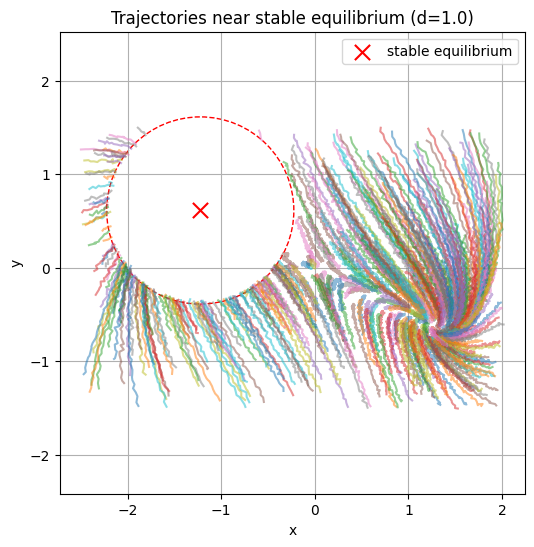

In [7]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda"
print(device)


data = torch.load("dataset.pt", map_location=device)

z0_train = data["z0_train"].to(device)
Z_train = data["Z_train"].to(device)

z0_test = data["z0_test"].to(device)
Z_test = data["Z_test"].to(device)

t_eval = data["t_eval"].to(device)

print("train:", z0_train.shape, Z_train.shape)
print("test :", z0_test.shape, Z_test.shape)
print("t_eval:", t_eval.shape)

print("\nTRAIN ranges:")
print("x0:", z0_train[:, 0].min().item(), z0_train[:, 0].max().item())
print("y0:", z0_train[:, 1].min().item(), z0_train[:, 1].max().item())

print("\nTEST ranges:")
print("x0:", z0_test[:, 0].min().item(), z0_test[:, 0].max().item())
print("y0:", z0_test[:, 1].min().item(), z0_test[:, 1].max().item())


eq_true  = torch.tensor([
    [0.0, 0.0], #saddle
    [1.2247449, -0.6123724],#stable
    [-1.2247449, 0.6123724],#stable
], dtype=torch.float32, device=device)
d = 1.0
eq = eq_true[2]

def truncate_near_equilibrium(Z, eq, d):
    Z_cut = Z.clone()

    for i in range(Z.size(0)):
        traj = Z[i]                      # [T, 2]
        dist = torch.norm(traj - eq, dim=1)
        hit = torch.where(dist < d)[0]

        if len(hit) > 0:
            k = hit[0].item()           
            Z_cut[i, k:] = traj[k]       

    return Z_cut

Z_cut = truncate_near_equilibrium(Z_test, eq, d)

plt.figure(figsize=(6, 6))

for i in range(min(600, Z_cut.size(0))):
    traj = Z_cut[i].detach().cpu().numpy()
    plt.plot(traj[:, 0], traj[:, 1], alpha=0.5)

plt.scatter(eq[0].item(), eq[1].item(),
            color='red', s=120, marker='x', label='stable equilibrium')


circle = plt.Circle((eq[0].item(), eq[1].item()),
                    d, fill=False, linestyle='--', color='red')
plt.gca().add_patch(circle)

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Trajectories near stable equilibrium (d={d})")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()



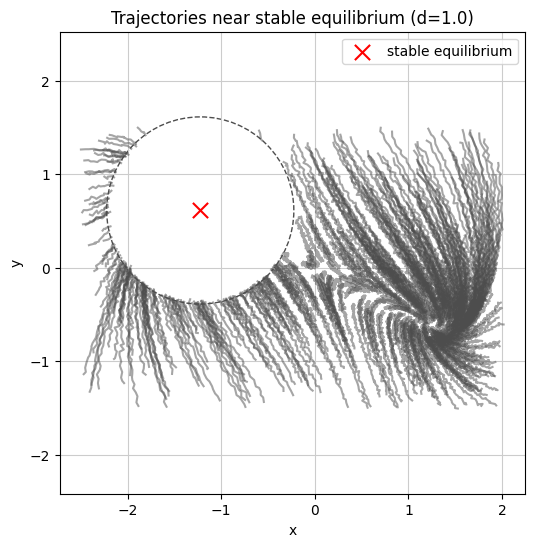

In [12]:
plt.figure(figsize=(6, 6))

for i in range(min(600, Z_cut.size(0))):
    traj = Z_cut[i].detach().cpu().numpy()
    plt.plot(traj[:, 0], traj[:, 1], color='0.3', alpha=0.5)  # серый

plt.scatter(eq[0].item(), eq[1].item(),
            color='red', s=120, marker='x', label='stable equilibrium')

circle = plt.Circle((eq[0].item(), eq[1].item()),
                    d, fill=False, linestyle='--', color='0.3')
plt.gca().add_patch(circle)

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Trajectories near stable equilibrium (d={d})")
plt.grid(True, color='0.8') 
plt.legend()
plt.axis("equal")
plt.show()

In [2]:
Z_train_cut = truncate_near_equilibrium(Z_train, eq, d)
Z_test_cut  = truncate_near_equilibrium(Z_test, eq, d)



train_loader_cut = DataLoader(
    TensorDataset(z0_train, Z_train_cut),
    batch_size=128,
    shuffle=True
)

test_loader_cut = DataLoader(
    TensorDataset(z0_test, Z_test_cut),
    batch_size=128,
    shuffle=False
)
class ODEmodel(nn.Module):
    def __init__(self, state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim + (1 if time_dependent else 0)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, t, z):
        if z.dim() == 1:
            z = z.unsqueeze(0)

        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z

        return self.net(h)


class NeuralODE(nn.Module):
    def __init__(self, func, use_adjoint=True, rtol=1e-3, atol=1e-4, method="dopri5"):
        super().__init__()
        self.func = func
        self.use_adjoint = use_adjoint
        self.rtol = rtol
        self.atol = atol
        self.method = method

    def forward(self, z0, t):
        solver = odeint_adjoint if self.use_adjoint else odeint
        Z = solver(self.func, z0, t, rtol=self.rtol, atol=self.atol, method=self.method)
        return Z.transpose(0, 1).contiguous()
    

def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count
    
true_equilibria = torch.tensor([
    [0.0, 0.0], #saddle
    [1.2247449, -0.6123724],#stable
    [-1.2247449, 0.6123724],#stable
], dtype=torch.float32, device=device)
def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

def find_equilibrium(func, x0, t0=0.0, steps=300, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

def analyze_one_equilibrium(func, x_true_eq, epoch, t0=0.0):
    print(f"\nEpoch {epoch}")
    
    x0 = x_true_eq + 0.2 * torch.randn_like(x_true_eq)

    x_eq, res = find_equilibrium(func, x0, t0=t0, steps=300, lr=0.02)
    err = torch.norm(x_eq - x_true_eq).item()

    J = jacobian_2d(func, x_eq, t0=t0)
    eigvals = torch.linalg.eigvals(J)

    print("Chosen equilibrium analysis")
    print("x_equilibrium      =", x_eq.detach().cpu().numpy())
    print("x_true_equilibrium =", x_true_eq.detach().cpu().numpy())
    print("||x_eq - x_true||  =", err)
    print("residual ||f(x)||  =", res)
    print("eigenvalues        =", eigvals.detach().cpu().numpy())

def train(model, train_loader, test_loader, t_eval, x_true_eq, epochs=600, lr=1e-3, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []

    for ep in range(1, epochs + 1):
        model.train()

        for z0, Z in train_loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()

            if clip_grad is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)

            optim.step()

        tr = evaluate(model, train_loader, t_eval)
        te = evaluate(model, test_loader, t_eval)

        train_losses.append(tr)
        test_losses.append(te)

        if ep % 10 == 0:
            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")
            analyze_one_equilibrium(model.func, x_true_eq, epoch=ep, t0=0.0)

    return model, train_losses, test_losses

In [3]:
func_cut = ODEmodel(hidden=64, time_dependent=True).to(device)
node_cut = NeuralODE(func_cut, use_adjoint=True).to(device)


chosen_eq = true_equilibria[2]
node_cut, train_losses_cut, test_losses_cut = train(
    node_cut,
    train_loader_cut,
    test_loader_cut,
    t_eval,
    x_true_eq=chosen_eq,
    epochs=600,
    lr=1e-3,
    tag=f"TRUNC_d={d}"
)

print("\nFinal MSE")
print("Train:", evaluate(node_cut, train_loader_cut, t_eval))
print("Test :", evaluate(node_cut, test_loader_cut,  t_eval))

/tmp/ipykernel_143598/381017722.py:39: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)


[TRUNC_d=1.0] Epoch 010 | train 0.044318 | test 0.039745

Epoch 10
Chosen equilibrium analysis
x_equilibrium      = [-0.8201822   0.25801864]
x_true_equilibrium = [-1.2247449  0.6123724]
||x_eq - x_true||  = 0.5378081202507019
residual ||f(x)||  = 0.013451050966978073
eigenvalues        = [-0.16720521+0.j -1.286637  +0.j]
[TRUNC_d=1.0] Epoch 020 | train 0.040568 | test 0.037389

Epoch 20
Chosen equilibrium analysis
x_equilibrium      = [-0.543031   0.1934221]
x_true_equilibrium = [-1.2247449  0.6123724]
||x_eq - x_true||  = 0.8001583218574524
residual ||f(x)||  = 0.025453409180045128
eigenvalues        = [-0.21500254+0.j -1.1396213 +0.j]
[TRUNC_d=1.0] Epoch 030 | train 0.034399 | test 0.032419

Epoch 30
Chosen equilibrium analysis
x_equilibrium      = [-0.5556455   0.21349615]
x_true_equilibrium = [-1.2247449  0.6123724]
||x_eq - x_true||  = 0.7789713144302368
residual ||f(x)||  = 0.03636076673865318
eigenvalues        = [-0.17582369+0.j -1.2559922 +0.j]
[TRUNC_d=1.0] Epoch 040 | train